# Feature engineering on the Nature 2024 dataset

Section 3 of the thesis plan: features computed from the sensor data, **beside** the raw channels, and what
they add. The fourteen per-leg features in four families (plus one bilateral feature) are the ones in the plan:

1. **Jerk and high-frequency content**: RMS jerk, peak jerk, acceleration high-frequency energy ratio, angular
   acceleration, gyro high-frequency ratio
2. **Polar phase space**: continuous gait phase, phase rate (cadence), phase monotonicity, ring radius variation
3. **Spectral**: dominant frequency, spectral entropy, stride regularity, step regularity
4. **Orientation from gravity**: thigh pitch

"What they add" is asked three ways, none of which trains the project's networks: does each feature measure what
its name says (section 2); what does each one separate, and is it new information or a re-expression of a raw
channel (sections 3–4); and does adding them help a participant-held-out probe identify the task family, the
controller class, and the hip moment (section 4). Everything uses the Nature data prepared in
[`01_dataset.ipynb`](01_dataset.ipynb); the definitions live in
[`ml/common/features.py`](../../../ml/common/features.py), checked by `test_features.py`.

## Findings at a glance

- **All 15 features are implemented and causal.** They are fourteen per leg plus bilateral step regularity, in
  `ml/common/features.py`. They cover 1.85 M windows in under a minute and cost at most about 25 µs per window
  (the spectral family), which is negligible next to a network.
- **They measure what they claim, after three fixes.**
  - The polar phase follows true gait phase to about 9% of a stride on level walking (7% ramp ascent, 14% ramp
    descent) after one offset that is nearly the same for every participant. That makes it a continuous gait phase
    without heel-strike detection.
  - Thigh pitch from gravity alone fails during gait (r = 0.38 with the hip angle in walking), so it is fused with
    the sagittal gyro (r = 0.92–0.98; 73° seated, about −5° standing).
  - Stride regularity, step regularity and dominant frequency report **0 when their search band holds no peak**,
    instead of the slope at the band edge, so their low end now means "no rhythm" rather than "slow" (section 2.4).
- **What separates the classes.** Stride regularity is the best single detector of cyclic, spline-controller tasks
  (AUROC 0.89), with step regularity close behind (0.88). Thigh pitch is the best single marker of the OOD-dangerous
  tasks (0.77), which are posture-driven.
- **The stride search stops too early for slow strides.** Its 0.5–1.6 s lag band misses strides of about 1.7–1.8 s,
  so about 12% of treadmill-walking windows and a third of the zeroed stair windows read 0 although they are
  rhythmic. That is the likely reason stride regularity's AUROC fell from 0.91 under the old edge readings.
- **What is new information.** Jerk RMS, peak jerk and angular acceleration are largely re-expressions of raw
  variability (|r| 0.89–0.92 with a raw window SD or maximum), and fused pitch largely re-expresses the hip angle
  (0.84). Entropy, the high-frequency ratios and ring variation carry information the raw summaries don't
  (|r| ≤ 0.56). Stride and step regularity track the thigh gyro's spread more now that windows without a rhythm
  read 0 (|r| 0.64–0.65, up from 0.41–0.48).
- **Effect on participant-held-out probes.**
  - Adding all features lifts task-family accuracy from 0.906 to 0.939 and controller-class accuracy from 0.843 to
    0.876, almost all of it from the spectral family.
  - Raw summaries given the same 3 s of history already reach 0.945 and 0.889. Longer context explains most of the
    gain; the spectral features add about half a point to one point on top (0.950 and 0.898).
  - Reporting 0 for "no peak" moved the probes that include raw data by at most 0.009, within noise; the
    engineered-only set lost 0.018 on controller class. That fits the edge values having carried a little "how slow"
    information, which the raw summaries also hold.
  - For the hip moment, all features together move R² from 0.725 to 0.734, and longer history lowers it (0.714).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, r2_score, roc_auc_score
from sklearn.model_selection import GroupKFold

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature'):              # dataset-agnostic helpers, then the Nature data access
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import nature_data as nt
import signals as sg
import features as ft          # ml/common/features.py

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
RATE = ft.RATE_HZ
GROUPS = {'walking': ['normal_walk', 'incline_walk', 'walk_backward', 'weighted_walk', 'dynamic_walk', 'obstacle_walk'],
          'stairs / curbs / step-ups': ['stairs', 'curb_up', 'curb_down', 'step_ups'],
          'squat / lift / sit / lunge': ['squats', 'lift_weight', 'sit_to_stand', 'lunges'],
          'jump / run / cut / shuffle': ['jump', 'tire_run', 'cutting', 'side_shuffle'],
          'standing / unstructured': ['poses', 'tug_of_war', 'push', 'twister', 'meander', 'start_stop', 'turn_and_step', 'ball_toss']}
GROUP_C = dict(zip(GROUPS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#4a3aa7']))
# Controller classes from the estimator-benchmark rule (notebook 01, 5.5): provisional, the thresholds are a choice.
CLASS = {**{t: 'ID-safe' for t in ['normal_walk', 'incline_walk', 'stairs', 'weighted_walk']},
         **{t: 'OOD-dangerous' for t in ['ball_toss', 'step_ups', 'tug_of_war', 'sit_to_stand']}}
FAMILIES = {'jerk / high-frequency': ['jerk_rms', 'jerk_peak', 'accel_hf_ratio', 'angular_accel_rms', 'gyro_hf_ratio'],
            'polar phase space': ['phase_sin', 'phase_cos', 'phase_rate_hz', 'phase_monotonicity', 'ring_cv'],
            'spectral': ['dominant_hz', 'spectral_entropy', 'stride_regularity'],
            'orientation': ['thigh_pitch']}

## 1. Definitions and computation

Every feature is evaluated at a window end *e* from samples at or before *e* only, so all of them can run causally
on the exo; window ends are every 10 samples (50 ms), as in the existing pipeline. Hip velocity is **recomputed** from
the angle (backward difference, causal 10 Hz Butterworth), because Nature's published velocity is half scale in most
sessions (notebook 01, 3.3). IMU axes are used in anatomical order: up = `y`, mediolateral = `z`, anterior = `x`.

| family | feature | definition (per window ending at *e*) | history |
|---|---|---|---|
| jerk / HF | RMS jerk | j(t) = ‖a(t) − a(t−1)‖·f_s ; √mean j² | 1 s |
| | peak jerk | max j(t) | 1 s |
| | accel HF ratio | share of ‖a‖ power above 10 Hz (mean removed, Hann taper) | 1 s |
| | angular acceleration | α(t) = ‖g(t) − g(t−1)‖·f_s ; √mean α² | 1 s |
| | gyro HF ratio | share of ‖g‖ power above 10 Hz | 1 s |
| polar phase | continuous phase | θ̃, ω̃ = hip angle and velocity scaled to their midrange and half-range ; φ = atan2(−ω̃, θ̃) ; sin φ(e), cos φ(e) | 2 s |
| | phase rate | total unwrapped advance of φ / (2π · window duration), cycles/s | 2 s |
| | phase monotonicity | share of samples where φ advances (1 = clean cycle, ≈ 0.5 = noise) | 2 s |
| | ring variation | SD / mean of r = √(θ̃² + ω̃²) (0 = perfect circle) | 2 s |
| spectral | dominant frequency | peak of the hip-angle spectrum in 0.3–3 Hz (parabolic interpolation); 0 if the maximum is on a band edge | 3 s |
| | spectral entropy | normalized Shannon entropy of the hip-angle spectrum, 0.25–20 Hz | 3 s |
| | stride regularity | largest autocorrelation of the hip angle over lags 0.5–1.6 s (overlap-normalized); 0 if the best lag is on a band edge | 3 s |
| | step regularity (bilateral) | autocorrelation of a_up,L + a_up,R at half the stride lag (±10%); 0 with no stride peak or a maximum on that window's edge | 3 s |
| orientation | thigh pitch | gravity angle ψ_g = atan2(a_anterior, a_up) fused with the mediolateral gyro: ψ_k = a·(ψ_k−1 + g_ML,k·dt) + (1 − a)·ψ_g,k, a = τ/(τ + dt), τ = 1 s | now |

Polar features are scaled to midrange and half-range rather than mean and SD because that makes a sinusoid an exact
unit circle whenever the 2 s window holds a full cycle; stride and step regularity normalize each lag by the energy
of its two overlapping segments, so they stay in [−1, 1]. A maximum on the edge of its search band is not a peak (the
spectrum or autocorrelation is still sloping there), so the three rhythm features report 0 for "no rhythm" rather than
the slope at the edge (section 2.4). The cell below builds (or reuses) the cached feature
table: one row per window end, both legs, plus summaries of the raw channels and the labels at the window end.

In [2]:
inv = nt.build_cache()
t0 = time.time()
built = nt.build_feature_cache(stride = 10)          # about a minute on the first run; reused while the code is unchanged
print(f'{built.windows.sum():,} windows from {len(built)} recordings ({time.time() - t0:.0f} s)')
f = pd.read_parquet(nt.CACHE / 'features')
meta = inv.set_index('rec')
rec = f['rec'].to_numpy()
f['task'] = meta['task'].to_numpy()[rec]
f['subject'] = meta['subject'].to_numpy()[rec]
f['group'] = f['task'].map({t: g for g, ts in GROUPS.items() for t in ts})
f['controller_class'] = f['task'].map(CLASS).fillna('OOD-safe')
LEFT = [f'{c}_l' for fam in FAMILIES.values() for c in fam] + ['step_regularity']
LEFT_PROFILE = [c for c in LEFT if not c.startswith(('phase_sin', 'phase_cos'))]   # phase itself is circular: no median, no ranking
ENG = [f'{c}_{s}' for fam in FAMILIES.values() for c in fam for s in nt.SIDES] + ['step_regularity']
RAW = [c for c in f if c.startswith('raw_')]
on = f[f['flag_l'] > 0].copy()                        # in-task windows (left leg's flag at the window end)
print(f'{len(on):,} in-task windows; engineered columns {len(ENG)}, raw-summary columns {len(RAW)}')
display(on[LEFT].isna().mean().rename('missing share (in task)').to_frame().T.round(3))

1,849,761 windows from 1358 recordings (45 s)


911,865 in-task windows; engineered columns 29, raw-summary columns 80


,jerk_rms_l,jerk_peak_l,accel_hf_ratio_l,angular_accel_rms_l,gyro_hf_ratio_l,phase_sin_l,phase_cos_l,phase_rate_hz_l,phase_monotonicity_l,ring_cv_l,dominant_hz_l,spectral_entropy_l,stride_regularity_l,thigh_pitch_l,step_regularity
missing share (in task),0.001,0.001,0.001,0.001,0.001,0.012,0.012,0.012,0.012,0.012,0.022,0.022,0.022,0.001,0.022


In [3]:
# Cost: single-core time per window, by family, on one long walking recording
r0 = inv.loc[inv.task == 'normal_walk', 'rec'].iloc[0]
df0 = pd.read_parquet(nt.CACHE / 'samples' / f'{r0:05d}.parquet')
leg = nt.get_leg_signals(df0, 'l')
ends0 = np.arange(ft.WINDOW['short'] - 1, len(df0), 10)
vel0 = ft.get_causal_velocity(leg['angle'])
timers = {'jerk / high-frequency': lambda: ft.get_jerk_features(leg['acc'], leg['gyr'], ends0),
          'polar phase space': lambda: ft.get_polar_features(leg['angle'], vel0, ends0),
          'spectral': lambda: ft.get_spectral_features(leg['angle'], ends0),
          'orientation': lambda: ft.get_thigh_pitch(leg['acc'][:, 0], leg['acc'][:, 2], ends0)}
cost = {}
for name, fn in timers.items():
    t0 = time.perf_counter()
    for _ in range(3):
        fn()
    cost[name] = (time.perf_counter() - t0) / 3 / len(ends0) * 1e6
display(pd.Series(cost, name = 'µs per window, one leg, batched on one core').round(1).to_frame().T)

,jerk / high-frequency,polar phase space,spectral,orientation
"µs per window, one leg, batched on one core",1.7,5.7,23.7,0.2


These are batched costs; a device evaluating one window at a time pays more per call, but the arithmetic per window
(a few FFTs of at most 600 samples) is small next to running a network.

## 2. Does each feature measure what its name says?

### 2.1 Features over time
Hip angle and a few features through three recordings: treadmill walking, jumping and sit-to-stand. Shaded spans are
out of task (flag off).

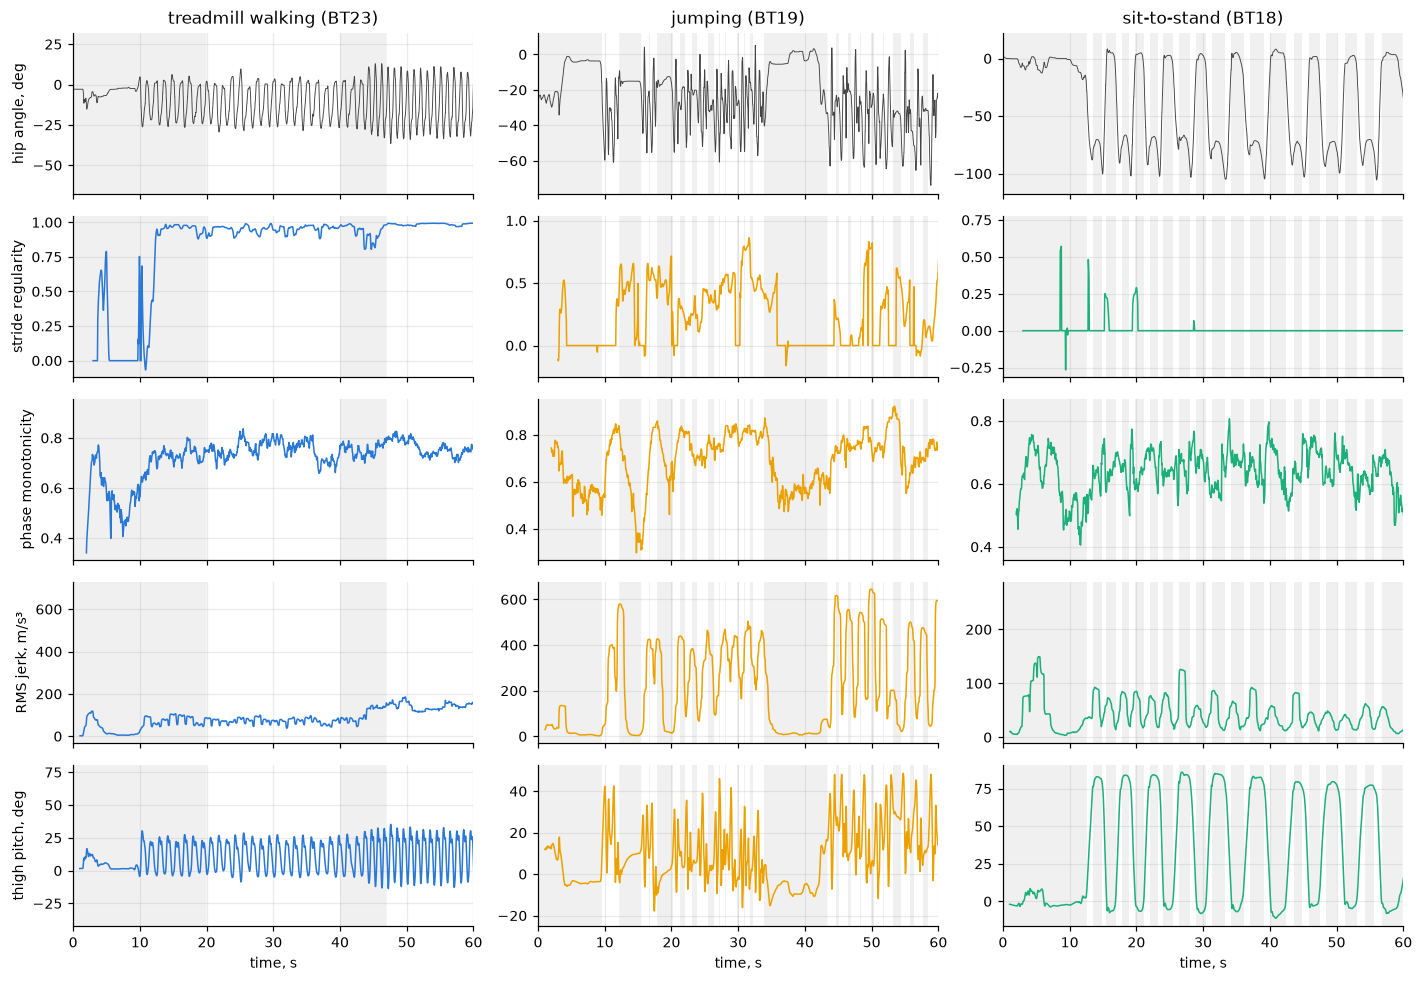

In [4]:
examples = {'normal_walk': 'treadmill walking', 'jump': 'jumping', 'sit_to_stand': 'sit-to-stand'}
show = [('hip_angle', 'hip angle, deg'), ('stride_regularity_l', 'stride regularity'), ('phase_monotonicity_l', 'phase monotonicity'),
        ('jerk_rms_l', 'RMS jerk, m/s³'), ('thigh_pitch_l', 'thigh pitch, deg')]
fig, axes = plt.subplots(len(show), 3, figsize = (13, 9), sharex = 'col')
for j, (task, title) in enumerate(examples.items()):
    r = inv[(inv.task == task) & (inv.phase == 'phase3')].sort_values('seconds').iloc[-1].rec
    sam = pd.read_parquet(nt.CACHE / 'samples' / f'{r:05d}.parquet', columns = ['hip_angle_l', 'flag_l'])
    fr = f[f.rec == r]
    t_s, t_f = np.arange(len(sam)) / RATE, fr['end'].to_numpy() / RATE
    span = min(60, t_s[-1])
    for i, (col, label) in enumerate(show):
        ax = axes[i, j]
        if col == 'hip_angle':
            ax.plot(t_s, sam.hip_angle_l, lw = .6, color = '#444')
        else:
            ax.plot(t_f, fr[col], lw = 1, color = GROUP_C[next(g for g, ts in GROUPS.items() if task in ts)])
        off = sam.flag_l.to_numpy() == 0
        ax.fill_between(t_s, 0, 1, where = off, transform = ax.get_xaxis_transform(), color = '#000', alpha = .06, lw = 0)
        ax.set_xlim(0, span)
        if j == 0:
            ax.set_ylabel(label)
        if i == 0:
            ax.set_title(f'{title} ({meta.loc[r, "subject"]})')
    axes[-1, j].set_xlabel('time, s')
plt.tight_layout(); plt.show()

### 2.2 Polar phase against true gait phase
Nature has no gait-phase labels, but the previous dataset does: `gp_hs`, the fraction of the stride since heel strike,
from its force plates. The same phase feature, run on its treadmill trials and compared with 2π·gp after removing one
constant offset per trial:

In [5]:
sinv = nt.build_scirob_cache()
rows = []
for r in sinv[(sinv['mode'].isin(['LG', 'RA', 'RD'])) & (sinv.speed > 0)].itertuples():
    folder = nt.SCIROB / r.path
    ang = np.degrees(pd.read_csv(folder / 'exo.csv', usecols = ['enc_angle_l'])['enc_angle_l'].to_numpy())
    gp = pd.read_csv(folder / 'gp.csv', usecols = ['gp_hs_l'])['gp_hs_l'].to_numpy()
    ends = np.arange(ft.WINDOW['polar'] - 1, len(ang), 10)
    pol = ft.get_polar_features(ang, ft.get_causal_velocity(ang), ends)
    diff = np.angle(np.exp(1j * (np.arctan2(pol['phase_sin'], pol['phase_cos']) - 2 * np.pi * gp[ends])))
    diff = diff[np.isfinite(diff)]
    if len(diff) > 50:
        offset = np.angle(np.mean(np.exp(1j * diff)))
        resid = np.angle(np.exp(1j * (diff - offset)))
        rows.append(dict(mode = r.mode, subject = r.subject, speed = r.speed, offset_deg = np.degrees(offset),
                         rms_error_deg = np.degrees(np.sqrt(np.mean(resid ** 2)))))
phase_check = pd.DataFrame(rows)
summary = phase_check.groupby('mode').agg(trials = ('subject', 'size'), offset_deg = ('offset_deg', 'median'),
                                          rms_error_deg = ('rms_error_deg', 'median'))
summary['rms_error_% of stride'] = summary.rms_error_deg / 3.6
display(summary.round(1))
print('per-participant offset (deg):', phase_check.groupby('subject').offset_deg.median().describe()[['min', '50%', 'max']].round(1).to_dict())
on_w = on[on.task == 'normal_walk']
print(f"Nature walking: phase rate vs dominant frequency r = {sg.get_corr(on_w.phase_rate_hz_l, on_w.dominant_hz_l):.2f}, "
      f"median |difference| {np.nanmedian(np.abs(on_w.phase_rate_hz_l - on_w.dominant_hz_l)):.3f} Hz")

,trials,offset_deg,rms_error_deg,rms_error_% of stride
mode,,,,
LG,207,-141.2,32.8,9.1
RA,120,-163.5,26.5,7.4
RD,119,-118.9,48.9,13.6


per-participant offset (deg): {'min': -152.3, '50%': -139.9, 'max': -124.2}
Nature walking: phase rate vs dominant frequency r = 0.80, median |difference| 0.058 Hz


The polar phase follows true gait phase to within roughly a tenth of a stride, with an offset that is nearly the
same for every participant, so one calibration constant turns it into gait phase without heel-strike detection.
It degrades on ramp descent, where the hip trajectory is least sinusoidal. Its cadence agrees with the spectral
cadence on Nature walking.

### 2.3 Thigh pitch against posture

In [6]:
rows = []
for task in ['normal_walk', 'incline_walk', 'stairs', 'sit_to_stand', 'squats']:
    for r in inv.loc[inv.task == task, 'rec'].iloc[:20]:
        sam = pd.read_parquet(nt.CACHE / 'samples' / f'{r:05d}.parquet')
        leg, idx = nt.get_leg_signals(sam, 'l'), np.arange(len(sam))
        hip, in_task = sam.hip_angle_l.to_numpy(), sam.flag_l.to_numpy() > 0
        still = np.abs(leg['gyr'][:, 1]) < 5
        gravity = ft.get_thigh_pitch(leg['acc'][:, 0], leg['acc'][:, 2], idx)
        fused = ft.get_thigh_pitch(leg['acc'][:, 0], leg['acc'][:, 2], idx, gyro_ml = leg['gyr'][:, 1])
        seated, standing = still & (hip < -60), still & (np.abs(hip) < 10)      # exo angle: extension positive
        rows.append({'r with hip angle, gravity only': sg.get_corr(np.where(in_task, gravity, np.nan), -hip),
                     'r with hip angle, fused': sg.get_corr(np.where(in_task, fused, np.nan), -hip),
                     'seated, still (deg)': np.nanmedian(fused[seated]) if seated.sum() > 50 else np.nan,
                     'standing, still (deg)': np.nanmedian(fused[standing]) if standing.sum() > 50 else np.nan, 'task': task})
display(pd.DataFrame(rows).groupby('task').median().round(2))

,"r with hip angle, gravity only","r with hip angle, fused","seated, still (deg)","standing, still (deg)"
task,,,,
incline_walk,0.51,0.94,44.80,-5.28
normal_walk,0.38,0.92,41.98,-5.10
sit_to_stand,0.81,0.93,73.08,-4.93
squats,0.87,0.97,57.70,-4.73
stairs,0.52,0.98,NaN,-11.03


The gravity angle alone is right when the leg is still (about 73° seated on these chairs, a few degrees below 0
standing, the offset being the IMU's mounting tilt; the seated column means something only for sit-to-stand and squats)
but wrong during gait, where the thigh's own acceleration is
read as gravity: it correlates only weakly with the hip angle in walking. Fusing in the gyro (a complementary filter:
the gyro carries the angle through movement, gravity removes its drift over about a second) keeps the static values
and tracks the hip angle closely in every task. That is the version in the feature table. It still is not the hip
angle: the difference is the pelvis's own tilt, which the exo encoder cannot see.

### 2.4 What the spectral features look like, task by task
One representative window for each of six contrasting tasks (Phase 3 participants; the window whose stride regularity is
the task's median), showing every quantity the spectral features are read from, computed exactly as
`ml/common/features.py` computes them:

1. the hip angle over the 3 s the features see (left solid, right dashed);
2. its power spectrum (mean removed, Hann taper), with the 0.3–3 Hz stride band shaded and the dominant frequency dotted;
3. its autocorrelation, with the 0.5–1.6 s stride-lag band shaded and the stride-regularity point marked;
4. the autocorrelation of both thighs' summed long-axis acceleration, with the half-stride lag (±10%) shaded where step
   regularity is read.

Filled markers are the values the features report. A **hollow** marker means the maximum fell on the edge of its search
band, so there is no peak inside it and the feature reports **0** instead; the dominant frequency likewise reads 0 when
the spectrum's in-band maximum sits at 0.3 or 3 Hz, and step regularity is 0 when there is no stride lag to halve.

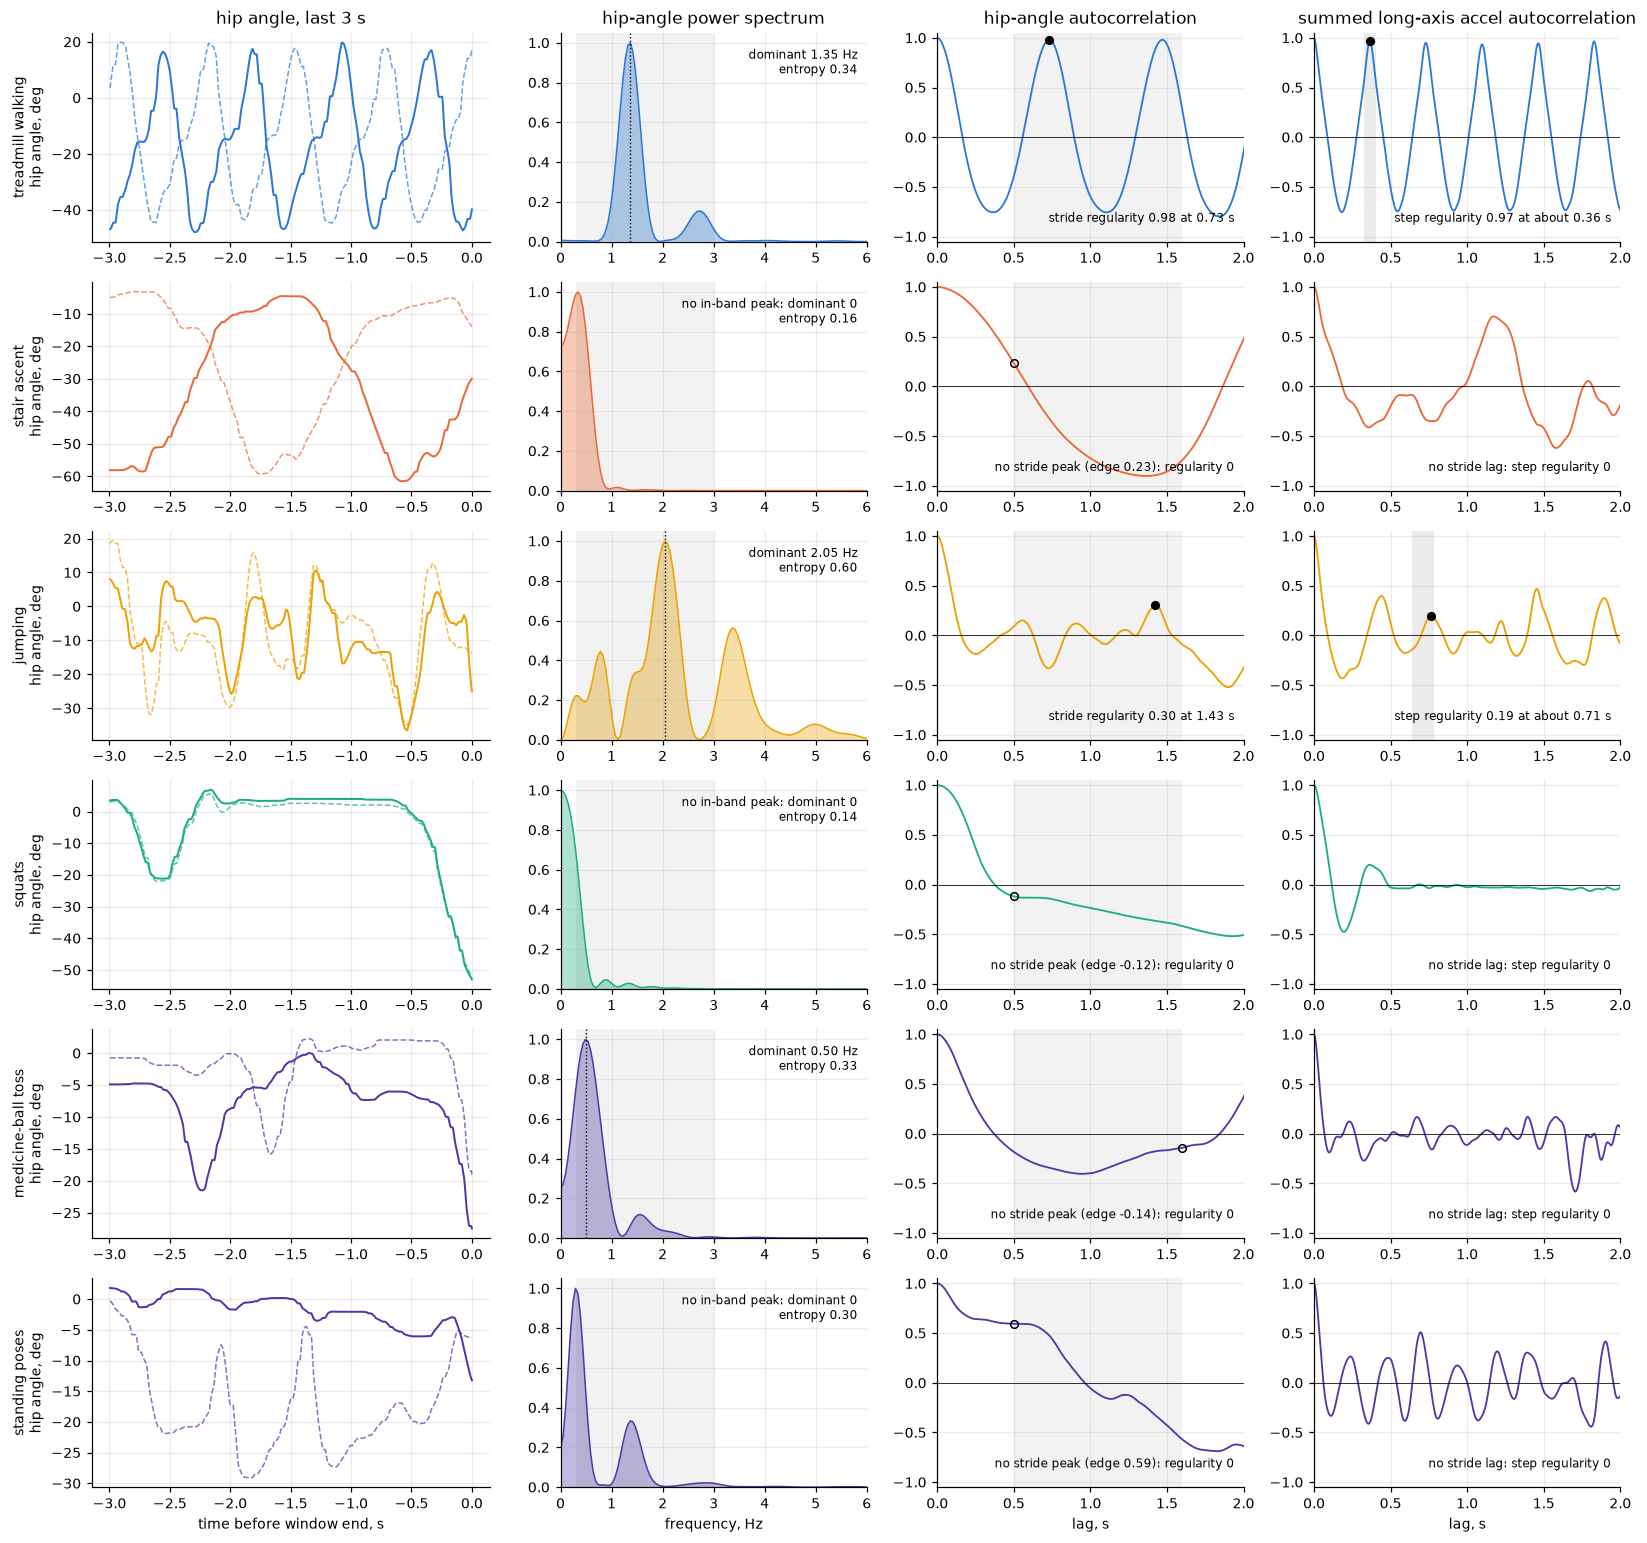

In [7]:
family_of = {t: g for g, ts in GROUPS.items() for t in ts}
EXAMPLES = [('normal_walk', None, 'treadmill walking'), ('stairs', 'up', 'stair ascent'), ('jump', None, 'jumping'),
            ('squats', None, 'squats'), ('ball_toss', None, 'medicine-ball toss'), ('poses', None, 'standing poses')]
L = ft.WINDOW['spectral']
t_rel, lags_s = (np.arange(L) - (L - 1)) / RATE, np.arange(L) / RATE
freq = np.fft.rfftfreq(ft.N_FFT, 1 / RATE)
lo, hi = ft.STRIDE_LAG_S
spec_cols = ['dominant_hz_l', 'spectral_entropy_l', 'stride_regularity_l', 'step_regularity']
pool = on.dropna(subset = spec_cols).assign(phase = lambda x: meta['phase'].to_numpy()[x['rec'].to_numpy()],
                                           stair_dir = lambda x: meta['stair_dir'].to_numpy()[x['rec'].to_numpy()])
fig, axes = plt.subplots(len(EXAMPLES), 4, figsize = (15, 2.35 * len(EXAMPLES)), gridspec_kw = {'width_ratios': [1.3, 1, 1, 1]})
for i, (task, direction, title) in enumerate(EXAMPLES):
    cand = pool[(pool.task == task) & (pool.phase == 'phase3') & ((pool.stair_dir == direction) if direction else True)]
    row = cand.iloc[int(np.argmin(np.abs(cand.stride_regularity_l - cand.stride_regularity_l.median()).to_numpy()))]
    sam = pd.read_parquet(nt.CACHE / 'samples' / f'{int(row.rec):05d}.parquet')
    sl = slice(int(row.end) - L + 1, int(row.end) + 1)
    ang_l, ang_r = sam.hip_angle_l.to_numpy()[sl], sam.hip_angle_r.to_numpy()[sl]
    color = GROUP_C[family_of[task]]
    ax = axes[i, 0]
    ax.plot(t_rel, ang_l, color = color, lw = 1.3); ax.plot(t_rel, ang_r, color = color, lw = 1, ls = '--', alpha = .7)
    ax.set_ylabel(f'{title}\nhip angle, deg')
    power = np.abs(np.fft.rfft((ang_l - ang_l.mean()) * np.hanning(L), ft.N_FFT)) ** 2
    ax = axes[i, 1]
    ax.fill_between(freq, power / power.max(), color = color, alpha = .35, lw = 0); ax.plot(freq, power / power.max(), color = color, lw = 1)
    ax.axvspan(*ft.STRIDE_BAND_HZ, color = '#000', alpha = .05, lw = 0)
    if row.dominant_hz_l > 0:
        ax.axvline(row.dominant_hz_l, color = 'k', lw = .9, ls = ':')
    dominant = f'dominant {row.dominant_hz_l:.2f} Hz' if row.dominant_hz_l > 0 else 'no in-band peak: dominant 0'
    ax.set_xlim(0, 6); ax.set_ylim(0, 1.05)
    ax.text(.97, .93, f'{dominant}\nentropy {row.spectral_entropy_l:.2f}', transform = ax.transAxes, ha = 'right', va = 'top', fontsize = 8)
    ac = ft.get_overlap_autocorrelation(ang_l[None, :])[0]
    band = np.flatnonzero((lags_s >= lo) & (lags_s <= hi))
    k = band[np.argmax(ac[band])]
    edge = k in (band[0], band[-1])
    ax = axes[i, 2]
    ax.plot(lags_s, ac, color = color, lw = 1.2); ax.axvspan(lo, hi, color = '#000', alpha = .05, lw = 0); ax.axhline(0, color = 'k', lw = .5)
    ax.plot(lags_s[k], ac[k], 'o', ms = 5, mec = 'k', mfc = 'none' if edge else 'k')
    ax.set_xlim(0, 2); ax.set_ylim(-1.05, 1.05)
    stride = f'no stride peak (edge {ac[k]:.2f}): regularity 0' if edge else f'stride regularity {row.stride_regularity_l:.2f} at {lags_s[k]:.2f} s'
    ax.text(.97, .08, stride, transform = ax.transAxes, ha = 'right', va = 'bottom', fontsize = 8)
    summed = sam.thigh_imu_l_accel_y.to_numpy()[sl] + sam.thigh_imu_r_accel_y.to_numpy()[sl]
    ac2 = ft.get_overlap_autocorrelation(summed[None, :])[0]
    ax = axes[i, 3]
    ax.plot(lags_s, ac2, color = color, lw = 1.2); ax.axhline(0, color = 'k', lw = .5)
    if edge:
        step = 'no stride lag: step regularity 0'
    else:
        half = lags_s[k] / 2
        win = np.flatnonzero((lags_s >= .9 * half) & (lags_s <= 1.1 * half))
        j = win[np.argmax(ac2[win])]
        ax.axvspan(.9 * half, 1.1 * half, color = '#000', alpha = .08, lw = 0)
        ax.plot(lags_s[j], ac2[j], 'o', ms = 5, mec = 'k', mfc = 'k' if row.step_regularity > 0 else 'none')
        step = f'step regularity {row.step_regularity:.2f} at about {half:.2f} s' if row.step_regularity > 0 else f'no step peak near {half:.2f} s: step regularity 0'
    ax.set_xlim(0, 2); ax.set_ylim(-1.05, 1.05)
    ax.text(.97, .08, step, transform = ax.transAxes, ha = 'right', va = 'bottom', fontsize = 8)
for j, title in enumerate(['hip angle, last 3 s', 'hip-angle power spectrum', 'hip-angle autocorrelation', 'summed long-axis accel autocorrelation']):
    axes[0, j].set_title(title)
for j, label in enumerate(['time before window end, s', 'frequency, Hz', 'lag, s', 'lag, s']):
    axes[-1, j].set_xlabel(label)
plt.tight_layout(); plt.show()

The same four features over every task (in-task windows, left leg; boxes 25–75%, whiskers 5–95%), tasks ordered by
median stride regularity and coloured by family:

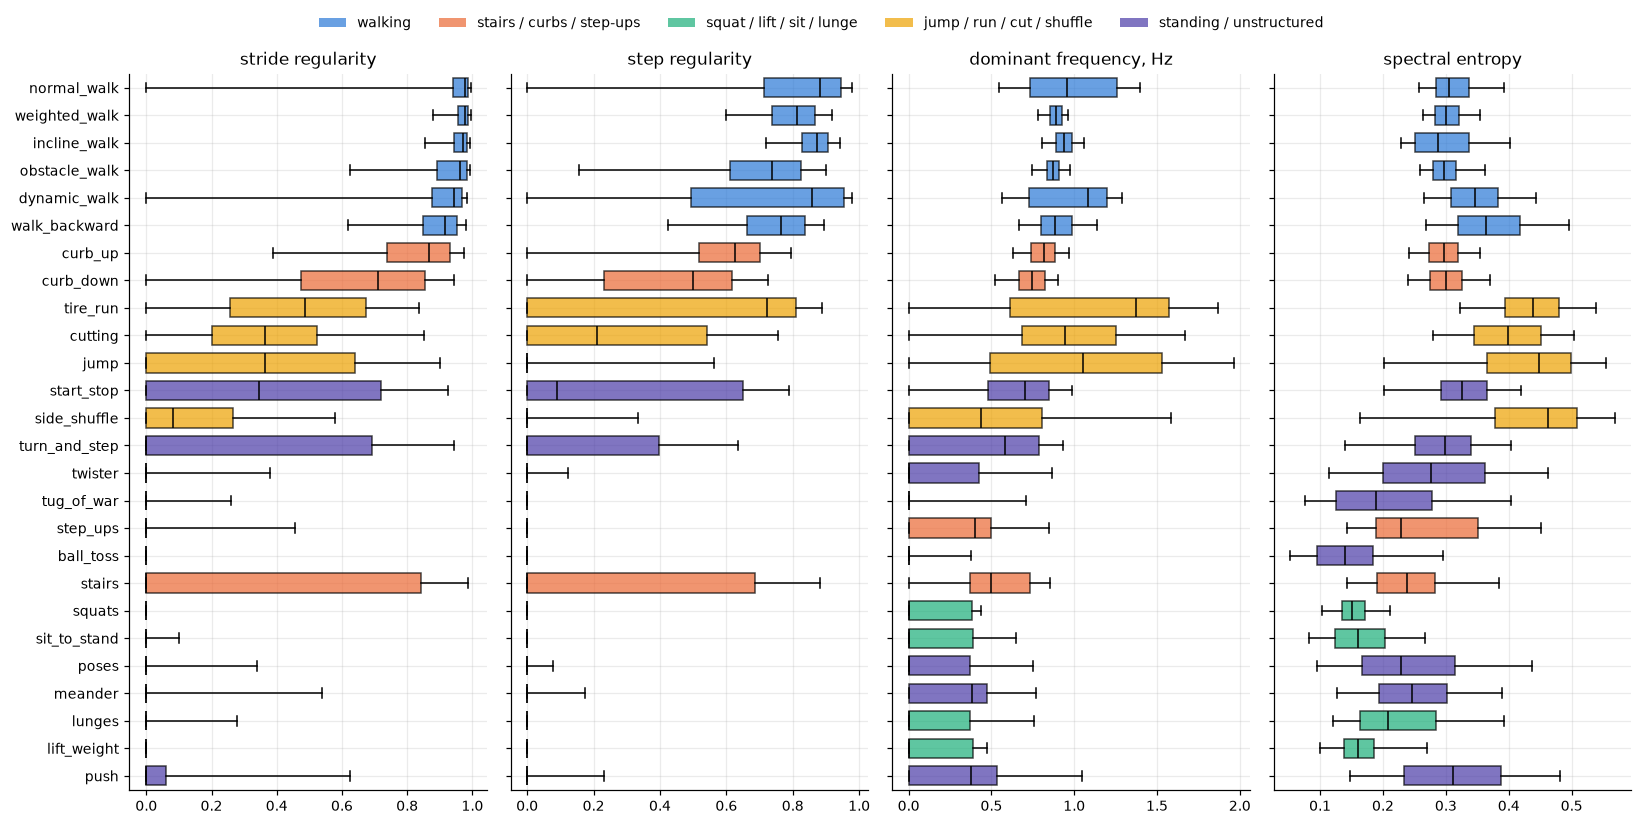

In [8]:
order = pool.groupby('task').stride_regularity_l.median().sort_values(ascending = False).index
sample = pool.groupby('task').sample(n = 4000, replace = True, random_state = 0)
names = {'stride_regularity_l': 'stride regularity', 'step_regularity': 'step regularity', 'dominant_hz_l': 'dominant frequency, Hz',
         'spectral_entropy_l': 'spectral entropy'}
fig, axes = plt.subplots(1, 4, figsize = (15, 7.5), sharey = True)
for ax, col in zip(axes, names):
    parts = ax.boxplot([sample.loc[sample.task == t, col].to_numpy() for t in order], orientation = 'horizontal', whis = (5, 95),
                       showfliers = False, patch_artist = True, widths = .7, medianprops = dict(color = 'k'))
    for patch, t in zip(parts['boxes'], order):
        patch.set(facecolor = GROUP_C[family_of[t]], alpha = .7)
    ax.set_title(names[col]); ax.set_yticks(range(1, len(order) + 1), order)
axes[0].invert_yaxis()
fig.legend([plt.Rectangle((0, 0), 1, 1, fc = c, alpha = .7) for c in GROUP_C.values()], list(GROUP_C), loc = 'upper center',
           ncol = len(GROUP_C), frameon = False, bbox_to_anchor = (.5, 1.0))
plt.tight_layout(rect = (0, 0, 1, .96)); plt.show()

What the two figures show:

- **Treadmill walking has a real stride peak.** In this window (a fast 0.73 s stride) the hip angle repeats with the
  legs in antiphase. The spectrum is one narrow peak at the stride frequency (1.35 Hz), and the autocorrelation climbs
  back to 0.98 one stride later. Step regularity is just as clean (0.97 at half a stride). The walking tasks' boxes
  sit between about 0.85 and 0.99.
- **Non-cyclic windows now read 0.** Stair ascent (this window), squats, the ball toss and standing poses have no
  peak in the 0.5–1.6 s lag band: their autocorrelation is still falling, or still rising, at the band edge. Before
  the fix they reported that edge value (0.3–0.5), which measured how slowly the hip angle changes, not a rhythm. Now
  85–99% of squat, sit-to-stand, step-up, pose and ball-toss windows read 0, and the dominant frequency is 0 in
  60–93% of squat, sit-to-stand, pose and ball-toss windows. A spectral peak inside the band can remain (the ball toss here, 0.50 Hz) while the stride search finds
  no repeat; the two answer different questions.
- **The 1.6 s upper lag is too short for slow strides.** About 12% of treadmill-walking windows read 0 because the
  stride is longer than 1.6 s (median about 1.7 s, with the autocorrelation peaking just beyond the band). Stairs read 0
  in about 60% of in-task windows: two thirds have no repeat in the band at all, and one third have strides of about
  1.8 s. Widening the band needs a longer window as well: at a 1.8 s lag, a 3 s window leaves only 1.2 s of overlap.
- **Step regularity lost its blind spot.** It used to read high in sit-to-stand and squats, where the summed
  acceleration only changes slowly; with no stride lag it is now 0 there.
- **Spectral entropy is not a cyclicity score.** It is lowest for slow single sweeps (squats, lifting, sit-to-stand,
  ball toss), middling for walking, and highest for impulsive tasks (jumping, running, cutting, side shuffle).
- **Jumping is periodic but bilateral.** Both legs move together, and the spectrum has several peaks (2.05 Hz the strongest here). The
  stride repeat is weak (0.30 at 1.43 s here), and a quarter of jumping windows have none.

So 0 now means "no rhythm this 3 s window can resolve at 0.5–1.6 s per stride". The remaining blind spot is the upper
limit, where slow walking and stairs are read as no rhythm.

## 3. What each feature separates

### 3.1 Profiles by task family
Median of each feature (left leg, in task) per family, standardized across families so one colour scale fits all.
The phase itself (sin, cos) is left out here and in 3.2: it says *where* in the cycle a window ends, which has no
meaningful median or class ranking; it appears again in 3.4 and section 4.

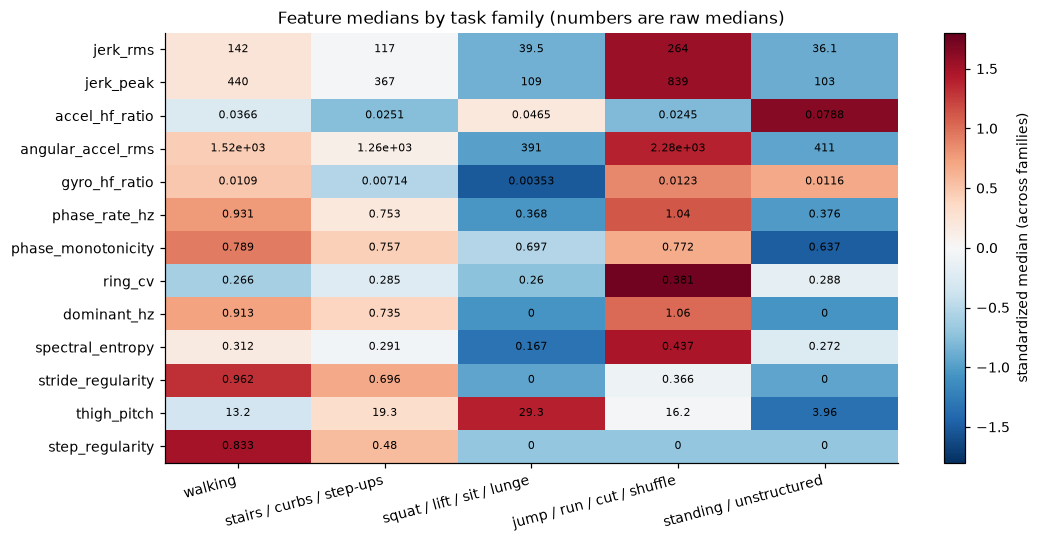

In [9]:
med = on.groupby('group')[LEFT_PROFILE].median().loc[list(GROUPS)]
z = (med - med.mean()) / med.std()
fig, ax = plt.subplots(figsize = (10, 5))
im = ax.imshow(z.T.to_numpy(), cmap = 'RdBu_r', vmin = -1.8, vmax = 1.8, aspect = 'auto')
ax.set_yticks(range(len(LEFT_PROFILE)), [c.removesuffix('_l') for c in LEFT_PROFILE]); ax.set_xticks(range(len(GROUPS)), list(GROUPS), rotation = 15, ha = 'right')
for i in range(len(LEFT_PROFILE)):
    for j in range(len(GROUPS)):
        ax.text(j, i, f'{med.iloc[j, i]:.3g}', ha = 'center', va = 'center', fontsize = 7)
ax.grid(False); plt.colorbar(im, ax = ax, label = 'standardized median (across families)')
ax.set_title('Feature medians by task family (numbers are raw medians)'); plt.tight_layout(); plt.show()

### 3.2 Separating the controller classes, one feature at a time
AUROC of each feature alone, in-task windows: cyclic tasks (ID-safe) against the rest, and the four OOD-dangerous tasks
against the rest. 0.5 is no separation; values below 0.5 mean the feature is *lower* in the class.

In [10]:
s = on.sample(300_000, random_state = 0)
rows = []
for c in LEFT_PROFILE:
    ok = s[c].notna()
    rows.append(dict(feature = c.removesuffix('_l'), family = next(k for k, v in FAMILIES.items() if c.removesuffix('_l') in v) if c != 'step_regularity' else 'spectral',
                     **{'cyclic (ID-safe) vs rest': roc_auc_score(s.controller_class[ok] == 'ID-safe', s[c][ok]),
                        'OOD-dangerous vs rest': roc_auc_score(s.controller_class[ok] == 'OOD-dangerous', s[c][ok])}))
auroc = pd.DataFrame(rows).set_index('feature')
auroc['separation (cyclic)'] = (auroc['cyclic (ID-safe) vs rest'] - .5).abs() + .5
display(auroc.sort_values('separation (cyclic)', ascending = False).drop(columns = 'separation (cyclic)').round(3))

,family,cyclic (ID-safe) vs rest,OOD-dangerous vs rest
feature,,,
stride_regularity,spectral,0.889,0.222
step_regularity,spectral,0.880,0.255
dominant_hz,spectral,0.791,0.198
angular_accel_rms,jerk / high-frequency,0.789,0.192
jerk_rms,jerk / high-frequency,0.774,0.220
jerk_peak,jerk / high-frequency,0.766,0.226
phase_rate_hz,polar phase space,0.765,0.201
phase_monotonicity,polar phase space,0.733,0.312
ring_cv,polar phase space,0.364,0.460


### 3.3 New information, or a re-expression of a raw channel?
For each feature, its strongest correlation with any of the 80 raw-channel window summaries (last value, mean, SD,
min, max of each of the 16 inputs). Near 1 means the feature is mostly a raw summary in disguise; low means it carries
something a summary of single channels does not.

In [11]:
s2 = on.sample(200_000, random_state = 1)
rows = []
for c in LEFT:
    r = s2[RAW].corrwith(s2[c]).abs()
    rows.append(dict(feature = c.removesuffix('_l'), max_abs_r = r.max(), closest_raw_summary = r.idxmax().removeprefix('raw_')))
redundancy = pd.DataFrame(rows).set_index('feature').sort_values('max_abs_r')
display(redundancy.round(2))

,max_abs_r,closest_raw_summary
feature,,
gyro_hf_ratio,0.23,hip_angle_l_sd
ring_cv,0.25,thigh_imu_r_accel_y_min
accel_hf_ratio,0.35,thigh_imu_l_accel_x_sd
spectral_entropy,0.56,thigh_imu_l_accel_y_max
phase_monotonicity,0.56,thigh_imu_l_gyro_z_sd
phase_cos,0.60,hip_angle_l_last
stride_regularity,0.64,thigh_imu_r_gyro_z_sd
step_regularity,0.65,thigh_imu_r_gyro_z_sd
dominant_hz,0.67,thigh_imu_l_gyro_z_sd


### 3.4 Relation to the hip moment
Correlation of each feature with the biological hip moment at the window end (extension positive), by task family,
next to the best raw channel's value (the window-end sample of the hip angle; notebook 01, 6.2 reports lagged values).

In [12]:
moment = -on['bio_l']
rows = []
for g, sub in on.groupby('group'):
    m = moment.loc[sub.index]
    row = {c.removesuffix('_l'): abs(sg.get_corr(sub[c], m)) for c in LEFT}
    row['hip angle (raw, window end)'] = abs(sg.get_corr(sub['raw_hip_angle_l_last'], m))
    rows.append(pd.Series(row, name = g))
mom = pd.DataFrame(rows).loc[list(GROUPS)].T
display(mom.round(2))

,walking,stairs / curbs / step-ups,squat / lift / sit / lunge,jump / run / cut / shuffle,standing / unstructured
jerk_rms,0.02,0.09,0.06,0.00,0.07
jerk_peak,0.03,0.10,0.04,0.03,0.07
accel_hf_ratio,0.09,0.09,0.10,0.03,0.04
angular_accel_rms,0.02,0.06,0.00,0.02,0.02
gyro_hf_ratio,0.13,0.17,0.00,0.00,0.07
phase_sin,0.32,0.27,0.11,0.13,0.22
phase_cos,0.39,0.30,0.41,0.41,0.25
phase_rate_hz,0.05,0.12,0.14,0.07,0.10
phase_monotonicity,0.04,0.04,0.01,0.06,0.11
ring_cv,0.02,0.17,0.11,0.03,0.05


## 4. Effect: do the features help a model that already has the raw data?

Participant-held-out probes (five folds, grouped by person, so no participant is on both sides). The probe is a
gradient-boosted tree ensemble: nonlinear, insensitive to scaling, quick, and not one of the project's networks, so
this asks whether the information is *there and usable*, not what a retrained network would reach. Three targets,
all on the same (about) 90,000 in-task windows:

- **task family** (5 classes, balanced accuracy)
- **controller class** (ID-safe / OOD-safe / OOD-dangerous, balanced accuracy)
- **hip moment** at the window end (R², overall and per family)

Feature sets: the 80 raw-channel summaries; the 29 engineered features alone; both; and the raw summaries plus one
family at a time. The spectral features see 3 s of history while the raw summaries see 1 s, so two controls separate
the features from the longer context: the same raw summaries computed over 3 s, alone and with the spectral family.

In [13]:
cols_of = lambda fam: [f'{c}_{s}' for c in FAMILIES[fam] for s in nt.SIDES] + (['step_regularity'] if fam == 'spectral' else [])
d = on.dropna(subset = ENG + RAW).sample(90_000, random_state = 0).reset_index(drop = True)
d['moment'] = -d['bio_l']
# control: the same raw summaries over the spectral features' 3 s history, for the sampled windows only
parts = []
for r, g in d.groupby('rec'):
    sam = pd.read_parquet(nt.CACHE / 'samples' / f'{r:05d}.parquet')
    parts.append(nt.get_raw_summaries(sam, g['end'].to_numpy(), ft.WINDOW['spectral']).set_index(g.index))
RAW3 = [c.replace('raw_', 'raw3s_') for c in RAW]
d = d.join(pd.concat(parts).set_axis(RAW3, axis = 1))
d = d.dropna(subset = RAW3).reset_index(drop = True)
SETS = {'raw summaries': RAW, 'engineered only': ENG, 'raw + engineered': RAW + ENG, **{f'raw + {fam}': RAW + cols_of(fam) for fam in FAMILIES},
        'raw summaries, 3 s': RAW3, 'raw 3 s + spectral': RAW3 + cols_of('spectral')}
folds = list(GroupKFold(5).split(d, groups = d['subject']))
rows = []
t0 = time.time()
for name, X in SETS.items():
    res = {'feature set': name, 'columns': len(X)}
    for target in ('group', 'controller_class', 'moment'):
        is_reg = target == 'moment'
        ok = d[target].notna().to_numpy()
        pred = np.full(len(d), np.nan) if is_reg else np.empty(len(d), dtype = object)
        for tr, te in folds:
            tr = tr[ok[tr]]
            model = (HistGradientBoostingRegressor if is_reg else HistGradientBoostingClassifier)(max_iter = 150, random_state = 0)
            pred[te] = model.fit(d.loc[tr, X], d.loc[tr, target]).predict(d.loc[te, X])
        if is_reg:
            res['moment R²'] = r2_score(d.moment[ok], pred[ok])
            for g, gi in d[ok].groupby('group').groups.items():
                res[f'R² {g}'] = r2_score(d.moment[gi], pred[gi])
        else:
            res[f'{target.replace("_", " ")} bal. acc.'] = balanced_accuracy_score(d[target], pred)
    rows.append(res)
probe = pd.DataFrame(rows).set_index('feature set')
print(f'{len(SETS)} feature sets x 3 targets x 5 folds in {time.time() - t0:.0f} s')
display(probe.round(3))

9 feature sets x 3 targets x 5 folds in 499 s


,columns,group bal. acc.,controller class bal. acc.,moment R²,R² jump / run / cut / shuffle,R² squat / lift / sit / lunge,R² stairs / curbs / step-ups,R² standing / unstructured,R² walking
feature set,,,,,,,,,
raw summaries,80,0.906,0.843,0.725,0.530,0.772,0.634,0.639,0.723
engineered only,29,0.871,0.823,0.603,0.343,0.652,0.499,0.407,0.643
raw + engineered,109,0.939,0.876,0.734,0.548,0.780,0.646,0.637,0.735
raw + jerk / high-frequency,90,0.906,0.841,0.726,0.529,0.773,0.638,0.636,0.728
raw + polar phase space,90,0.917,0.852,0.726,0.533,0.769,0.639,0.635,0.729
raw + spectral,87,0.936,0.875,0.728,0.540,0.771,0.635,0.638,0.732
raw + orientation,82,0.904,0.845,0.730,0.539,0.779,0.641,0.635,0.728
"raw summaries, 3 s",80,0.945,0.889,0.714,0.526,0.761,0.615,0.608,0.713
raw 3 s + spectral,87,0.950,0.898,0.717,0.534,0.762,0.613,0.610,0.718


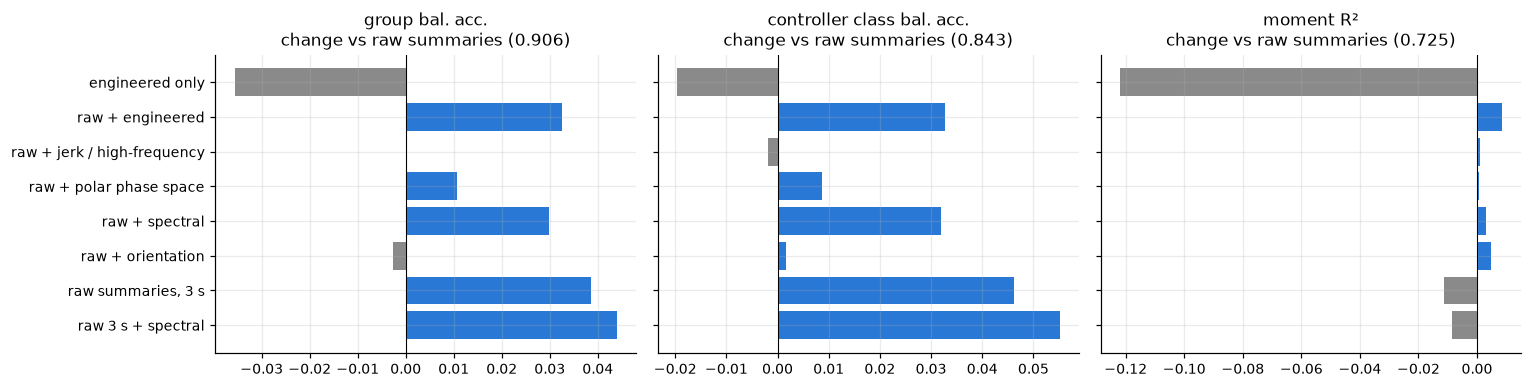

In [14]:
base = probe.loc['raw summaries']
gain = probe.drop(columns = 'columns').sub(base.drop('columns'), axis = 1).drop(index = 'raw summaries')
fig, axes = plt.subplots(1, 3, figsize = (14, 3.6), sharey = True)
for ax, col in zip(axes, ['group bal. acc.', 'controller class bal. acc.', 'moment R²']):
    vals = gain[col]
    ax.barh(vals.index, vals, color = ['#8a8a8a' if v < 0 else '#2a78d6' for v in vals])
    ax.axvline(0, color = 'k', lw = .7); ax.set_title(f'{col}\nchange vs raw summaries ({base[col]:.3f})')
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()

## 5. What to keep

| family | keep? | why |
|---|---|---|
| polar phase space | **keep**, as a controller signal | Continuous gait phase within about a tenth of a stride without heel-strike detection; small help for classification |
| spectral (stride and step regularity, dominant frequency) | **keep**, and extend the stride band | The only features that add to the raw data for task and controller classification, mostly because they summarize 3 s. Strides longer than 1.6 s read as no rhythm (section 2.4) |
| orientation (fused thigh pitch) | **keep**, cheap and interpretable | Best single marker of the posture-driven OOD-dangerous tasks; little added for the moment beyond the hip angle |
| jerk and high-frequency content | **deprioritize** | Jerk and angular acceleration repeat the raw window's variability (no probe gain); the high-frequency ratios are shares, so quiet signals read as noise. Worth keeping only if a fault detector needs them |

**Design implications**

- **Context length is the bigger lever for classification.** Either give the classifier or novelty model a longer
  input than the current 1 s window, or feed it a few long-context summaries (stride regularity, step regularity,
  dominant frequency) beside the 1 s raw window.
- **For the moment estimator and forecaster, no engineered feature adds materially.** A model reading the raw 1 s
  window already has what these features summarize, so effort is better spent on the model than on these inputs.

**Limits of this test**

- The probes are gradient-boosted trees on window summaries, not the project's networks.
- One sample of about 90,000 windows was used, so differences under about 0.01 are within noise.
- The controller classes come from notebook 01's provisional estimator-benchmark rule.
- The stride search covers 0.5–1.6 s, so slower strides read 0: about 12% of treadmill-walking windows and a third
  of the zeroed stair windows. A longer lag band needs a longer window, which changes every spectral feature.
- Not done here: retraining a network with the features, and scoring jerk and the high-frequency ratios against the
  injected sensor faults, which is where those two should matter most.